# Where Honduras' pine is harvested

A forest **operating plan** (*plan operativo anual*, POA) is the permit to harvest
one area of a forest management plan in a given year. ICF, the national forest
authority, publishes the approved POAs as a public map layer [@icf-planes-operativos],
and the department boundaries on the same server [@icf-limite-departamentos].

The question for today's theme: **does the authorized harvest spread across the
pine forest, or does it gather in a few places?** The answer is the second, and
this notebook measures how much.

In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib import patheffects
import numpy as np
import pandas as pd
from sklearn.cluster import HDBSCAN

WFS = "https://geoserver.icf.gob.hn/icfpub/wfs"
CRS = 32616  # WGS 84 / UTM zone 16N, the layer's own CRS, in metres


def read_layer(name: str) -> gpd.GeoDataFrame:
    """Read a whole layer from ICF's public WFS as GeoJSON."""
    url = (
        f"{WFS}?service=WFS&version=2.0.0&request=GetFeature"
        f"&typeNames={name}&outputFormat=application/json"
    )
    return gpd.read_file(url).to_crs(CRS)


raw = read_layer("planes_operativos_gp")
departments = read_layer("limite_departamentos_gp")
print(f"{len(raw):,} POA polygons, {raw.fech_apro.min()} to {raw.fech_apro.max()}")

1,729 POA polygons, 2017-12-04 00:00:00 to 2026-09-28 00:00:00


## Transform: one row per plan

Two things in the raw layer would bias the totals:

1. **Repeated plans.** A few `cod_poa` codes appear more than once: the same plan
   split into several polygons, each carrying the plan's full volume. Summing them
   would count that volume twice. They are merged into one plan, keeping the
   largest volume reported.
2. **Implausible volume per hectare.** A handful of plans report hundreds or
   thousands of m³/ha, most likely a polygon digitized smaller than the real
   area. Their volume stays (it comes from the plan, not the polygon), and they
   are only flagged.

In [2]:
raw["geometry"] = raw.geometry.make_valid()
repeated = raw.cod_poa.duplicated(keep=False)
print(f"{raw[repeated].cod_poa.nunique()} codes repeated in {repeated.sum()} polygons")

poa = raw.dissolve(
    by="cod_poa",
    aggfunc={
        "volu_total": "max",
        "arb_cortar": "max",
        "fech_apro": "first",
        "depto": "first",
        "tipo_bosq": "first",
        "tene_priv": "first",
        "tene_ejid": "first",
        "tene_naci": "first",
    },
).reset_index()
poa["area_ha"] = poa.area / 10_000
poa["year"] = pd.to_datetime(poa.fech_apro).dt.year
poa["m3_ha"] = poa.volu_total / poa.area_ha

flagged = poa.m3_ha > 150
print(
    f"{len(poa):,} plans; {flagged.sum()} flagged above 150 m³/ha "
    f"({poa.loc[flagged, 'volu_total'].sum():,.0f} m³ kept)"
)
print(f"Total authorized volume: {poa.volu_total.sum():,.0f} m³")

26 codes repeated in 52 polygons


1,703 plans; 7 flagged above 150 m³/ha (16,362 m³ kept)
Total authorized volume: 3,127,258 m³


## A quick profile

In [3]:
tenure = (
    poa[["tene_priv", "tene_ejid", "tene_naci"]]
    .eq("SI")
    .mean()
    .rename({"tene_priv": "private", "tene_ejid": "ejidal", "tene_naci": "national"})
)
print("Share of plans by tenure (a plan can have more than one):")
print((tenure * 100).round(1).to_string())
print("\nForest type:")
print(poa.tipo_bosq.value_counts().to_string())

profile = poa.groupby("year").agg(plans=("cod_poa", "size"), m3=("volu_total", "sum"))
profile

Share of plans by tenure (a plan can have more than one):
private     96.0
ejidal       2.4
national     1.6

Forest type:
tipo_bosq
Conifera       1686
Mixto            10
Latifoliado       7


,plans,m3
year,,
2017,1,418.553500
2018,1,4569.500000
2019,197,386576.293091
2020,144,306002.345300
2021,276,559691.264700
2022,239,402465.058150
2023,234,390144.209994
2024,196,319450.771125
2025,247,447175.198610


Almost every plan is in **pine** forest and on **private** land. The years
before 2019 hold only a couple of plans: the layer is, in practice, 2019 to
2026, and 2026 is still open.

## Clustering the plans

Each plan becomes one point (its polygon's centroid), and HDBSCAN groups the
points that sit close together [@campello2013], as implemented in scikit-learn
[@pedregosa2011]. Unlike k-means it does not need the number of groups in
advance, and it leaves isolated plans out as *noise*. Its one parameter is the
smallest group worth calling a cluster: here, **20 plans**.

In [4]:
MIN_CLUSTER = 20

points = np.c_[poa.centroid.x, poa.centroid.y]
poa["cluster"] = HDBSCAN(min_cluster_size=MIN_CLUSTER, copy=True).fit_predict(points)
print(f"{poa.cluster.max() + 1} clusters, {(poa.cluster < 0).sum()} plans outside them")

18 clusters, 496 plans outside them


## How concentrated is the harvest?

A cluster's footprint is the **concave hull** of its plans: the tightest outline
around them, which follows the shape of the group better than a convex hull.
Footprint is compared with the land area of Honduras (the department layer).

In [5]:
country_ha = departments.area.sum() / 10_000
total_m3 = poa.volu_total.sum()

clusters = (
    poa[poa.cluster >= 0]
    .dissolve(
        by="cluster",
        aggfunc={
            "cod_poa": "size",
            "volu_total": "sum",
            "depto": lambda s: s.mode()[0],
        },
    )
    .rename(columns={"cod_poa": "plans", "volu_total": "m3", "depto": "department"})
)
clusters["geometry"] = clusters.geometry.concave_hull(ratio=0.3)
clusters["area_share"] = clusters.area / 10_000 / country_ha
clusters["volume_share"] = clusters.m3 / total_m3
clusters = clusters.sort_values("m3", ascending=False)
clusters["rank"] = range(1, len(clusters) + 1)

TOP = 5
top = clusters.head(TOP)
headline = (
    f"{TOP} hotspots, {top.area_share.sum():.1%} of the country, "
    f"{top.volume_share.sum():.0%} of the authorized pine volume"
)
print(headline)
print(
    f"All {len(clusters)} clusters: {clusters.area_share.sum():.1%} of the land, "
    f"{clusters.volume_share.sum():.0%} of the volume"
)
clusters[["rank", "department", "plans", "m3", "area_share", "volume_share"]].round(3)

5 hotspots, 2.7% of the country, 40% of the authorized pine volume
All 18 clusters: 5.3% of the land, 67% of the volume


,rank,department,plans,m3,area_share,volume_share
cluster,,,,,,
14,1,Francisco Morazán,216,391344.931,0.009,0.125
11,2,El Paraíso,178,258349.135,0.006,0.083
8,3,Olancho,102,229897.407,0.003,0.074
16,4,Olancho,96,193365.834,0.004,0.062
13,5,Olancho,96,186327.074,0.004,0.060
12,6,Olancho,49,125792.458,0.001,0.040
3,7,Intibucá,81,124396.875,0.005,0.040
7,8,Olancho,47,83160.129,0.001,0.027
4,9,Yoro,50,80354.661,0.003,0.026


### Does the finding depend on the parameter?

A result that only holds for one setting is not a result. The same measure with
smaller and larger clusters, and with both hull types:

In [6]:
rows = []
for size in (10, 20, 40):
    labels = HDBSCAN(min_cluster_size=size, copy=True).fit_predict(points)
    grouped = poa.assign(c=labels)[labels >= 0].dissolve(
        by="c", aggfunc={"volu_total": "sum"}
    )
    for hull in ("convex", "concave"):
        shape = (
            grouped.convex_hull if hull == "convex" else grouped.concave_hull(ratio=0.3)
        )
        order = grouped.volu_total.sort_values(ascending=False).index[:TOP]
        rows.append(
            {
                "min_cluster_size": size,
                "hull": hull,
                "clusters": len(grouped),
                f"top {TOP} land share": shape.loc[order].area.sum()
                / 10_000
                / country_ha,
                f"top {TOP} volume share": grouped.volu_total.loc[order].sum()
                / total_m3,
            }
        )
pd.DataFrame(rows).round(3)

,min_cluster_size,hull,clusters,top 5 land share,top 5 volume share
0,10,convex,27,0.028,0.332
1,10,concave,27,0.020,0.332
2,20,convex,18,0.034,0.403
3,20,concave,18,0.027,0.403
4,40,convex,4,0.254,0.870
5,40,concave,4,0.166,0.870


With 10 or 20 plans per cluster the picture holds: the five largest hotspots
cover 2 to 3.5% of the land and hold a third to two fifths of the volume
(figures as of 2026-11-04). At 40 the clusters merge into a few regional blobs
and stop being hotspots, so 20 is the setting used.

## The map

The same map in English and Spanish: only the text changes.

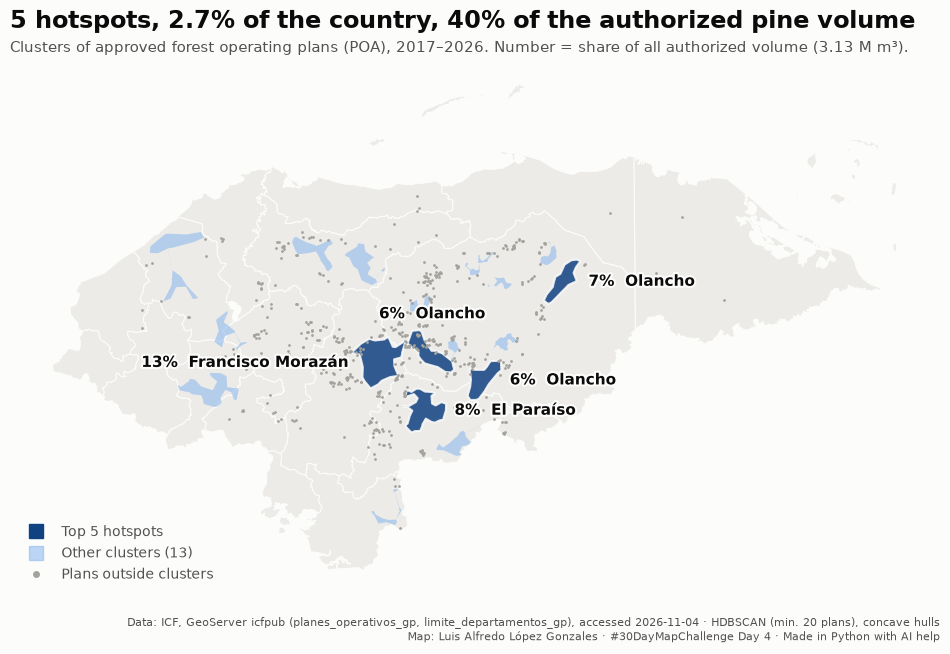

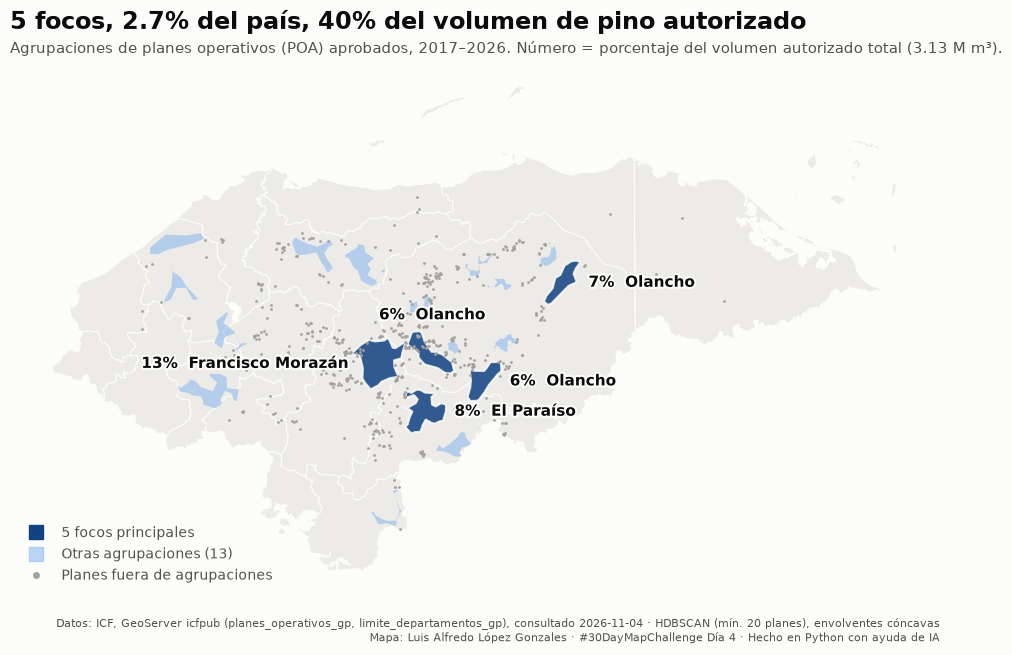

In [7]:
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#a3a29c"
SURFACE, LAND, EDGE = "#fcfcfb", "#ecebe7", "#fcfcfb"
HOT, OTHER = "#104281", "#86b6ef"

top_area, top_volume = top.area_share.sum(), top.volume_share.sum()
first_year, others = poa.year.min(), len(clusters) - TOP
TEXT = {
    "en": {
        "title": f"{TOP} hotspots, {top_area:.1%} of the country, "
        f"{top_volume:.0%} of the authorized pine volume",
        "subtitle": f"Clusters of approved forest operating plans (POA), {first_year}–2026. "
        f"Number = share of all authorized volume ({total_m3 / 1e6:.2f} M m³).",
        "top": f"Top {TOP} hotspots",
        "other": f"Other clusters ({others})",
        "outside": "Plans outside clusters",
        "credits": "Data: ICF, GeoServer icfpub (planes_operativos_gp, limite_departamentos_gp), "
        "accessed 2026-11-04 · HDBSCAN (min. 20 plans), concave hulls\n"
        "Map: Luis Alfredo López Gonzales · #30DayMapChallenge Day 4 · "
        "Made in Python with AI help",
    },
    "es": {
        "title": f"{TOP} focos, {top_area:.1%} del país, "
        f"{top_volume:.0%} del volumen de pino autorizado",
        "subtitle": f"Agrupaciones de planes operativos (POA) aprobados, {first_year}–2026. "
        f"Número = porcentaje del volumen autorizado total ({total_m3 / 1e6:.2f} M m³).",
        "top": f"{TOP} focos principales",
        "other": f"Otras agrupaciones ({others})",
        "outside": "Planes fuera de agrupaciones",
        "credits": "Datos: ICF, GeoServer icfpub (planes_operativos_gp, limite_departamentos_gp), "
        "consultado 2026-11-04 · HDBSCAN (mín. 20 planes), envolventes cóncavas\n"
        "Mapa: Luis Alfredo López Gonzales · #30DayMapChallenge Día 4 · "
        "Hecho en Python con ayuda de IA",
    },
}

# Label side per hotspot rank, set by eye for the data of 2026-11-04 so the
# central labels don't cross; any other rank goes to the right.
LABEL_SIDE = {1: "left", 4: "top"}


def draw_map(lang: str) -> plt.Figure:
    """Draw the hotspot map with its text in `lang` ("en" or "es")."""
    text = TEXT[lang]
    fig, ax = plt.subplots(figsize=(12, 8), facecolor=SURFACE)
    ax.set_facecolor(SURFACE)

    departments.simplify(200).plot(ax=ax, color=LAND, edgecolor=EDGE, linewidth=0.8)
    clusters.iloc[TOP:].plot(ax=ax, color=OTHER, alpha=0.55, edgecolor="none")
    top.plot(ax=ax, color=HOT, alpha=0.85, edgecolor=SURFACE, linewidth=1.5)
    outside = poa[poa.cluster < 0]
    ax.scatter(outside.centroid.x, outside.centroid.y, s=4, color=MUTED, linewidths=0)

    for _, row in top.iterrows():
        minx, miny, maxx, maxy = row.geometry.bounds
        side = LABEL_SIDE.get(row["rank"], "right")
        xy, offset, ha, va = {
            "right": ((maxx, (miny + maxy) / 2), (6, 0), "left", "center"),
            "left": ((minx, (miny + maxy) / 2), (-6, 0), "right", "center"),
            "top": (((minx + maxx) / 2, maxy), (0, 6), "center", "bottom"),
        }[side]
        ax.annotate(
            f"{row.volume_share:.0%}  {row.department}",
            xy=xy,
            xytext=offset,
            textcoords="offset points",
            ha=ha,
            va=va,
            fontsize=11,
            fontweight="bold",
            color=INK,
            path_effects=[patheffects.withStroke(linewidth=3, foreground=SURFACE)],
        )

    ax.text(
        0.0,
        1.06,
        text["title"],
        transform=ax.transAxes,
        fontsize=17,
        fontweight="bold",
        color=INK,
    )
    ax.text(
        0.0, 1.015, text["subtitle"], transform=ax.transAxes, fontsize=10.5, color=INK_2
    )

    handles = [
        plt.Line2D([], [], marker="s", ls="", ms=10, color=HOT, label=text["top"]),
        plt.Line2D(
            [],
            [],
            marker="s",
            ls="",
            ms=10,
            color=OTHER,
            alpha=0.55,
            label=text["other"],
        ),
        plt.Line2D([], [], marker="o", ls="", ms=4, color=MUTED, label=text["outside"]),
    ]
    ax.legend(
        handles=handles, loc="lower left", frameon=False, fontsize=10, labelcolor=INK_2
    )
    ax.text(
        1.0,
        -0.04,
        text["credits"],
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=8,
        color=INK_2,
    )

    ax.set_axis_off()
    ax.set_aspect("equal")
    return fig


for lang in TEXT:
    fig = draw_map(lang)
    fig.savefig(
        f"day04-clusters-{lang}.png", dpi=200, bbox_inches="tight", facecolor=SURFACE
    )
plt.show()

## What this map does not say

- **Approved, not harvested.** A POA authorizes a volume; how much was actually
  cut is not in this layer.
- **Published, not all.** These are the plans on ICF's public GeoServer as of
  2026-11-04; plans missing from it are missing here. 2026 is a partial year.
- **No plan is singled out.** The map shows groups, not owners or sites; the
  layer's site and tenure fields are only used in aggregate.
- **The footprint is a model.** Hull area depends on the hull and the parameter;
  the sensitivity table above shows the range.

## References

::: {#refs}
:::